# College Football Upset Vulnerability — Notebook 07: When Does Past-Season Performance Matter?


## 0. Load prior artifacts and lock the split plan



In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'

files = {
    'enhanced_features': PROCESSED / 'matchup_features_recent_history.csv',
    'previous_manifest': PROCESSED / 'recent_history_feature_manifest.json',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'split_manifest': PROCESSED / 'split_manifest.json',
    'notebook06_predictions': OUTPUT_DIR / 'recent_history_oof_predictions_2019_2023.csv',
}
for label, path in files.items():
    if not path.is_file():
        raise FileNotFoundError(f'Missing {label}: {path}. Run Notebook 06 export first.')

matchups = pd.read_csv(files['enhanced_features'], parse_dates=['date'], low_memory=False)
eligibility = pd.read_csv(files['eligibility'], low_memory=False)
manifest06 = json.loads(files['previous_manifest'].read_text(encoding='utf-8'))
split_plan = json.loads(files['split_manifest'].read_text(encoding='utf-8'))
previous_oof = pd.read_csv(files['notebook06_predictions'])
folds = split_plan['validation_folds']
TEST_YEARS = set(map(int, split_plan['test_seasons']))
BASE45 = list(manifest06['feature_sets']['baseline_45'])
PRIOR1 = list(manifest06['feature_sets']['prior_1season'])
PRIOR3 = list(manifest06['feature_sets']['prior_3seasons_decay'])

assert TEST_YEARS == {2024, 2025}
assert [int(f['validation_season']) for f in folds] == [2019,2020,2021,2022,2023]
assert len(BASE45) == 45
assert matchups.game_id.is_unique and eligibility.game_id.is_unique
assert len(matchups) == len(eligibility) == 18300
assert set(BASE45).issubset(matchups.columns)
assert set(PRIOR3).issubset(matchups.columns)
assert set(PRIOR1).issubset(matchups.columns)
print('Loaded:', f'{len(matchups):,}', 'matchups, with', len(BASE45), 'base features')
print('Validation years:', [int(f['validation_season']) for f in folds])
print('Reserved, not evaluated:', sorted(TEST_YEARS))
print('scikit-learn version:', sklearn.__version__)
display(matchups[['game_id','season','date','home','away','home_fbs_prior_games','away_fbs_prior_games']].head())

Mounted at /content/drive
Loaded: 18,300 matchups, with 45 base features
Validation years: [2019, 2020, 2021, 2022, 2023]
Reserved, not evaluated: [2024, 2025]
scikit-learn version: 1.6.1


,game_id,season,date,home,away,home_fbs_prior_games,away_fbs_prior_games
0,1,2004,2004-08-28,Miami (OH),Indiana State,0,0
1,2,2004,2004-08-28,Virginia Tech,USC,0,0
2,3,2004,2004-09-02,Arizona State,UTEP,0,0
3,4,2004,2004-09-02,Eastern Michigan,Buffalo,0,0
4,5,2004,2004-09-02,Utah,Texas A&M,0,0


## 1. Define pregame season stages and audit them



In [ ]:
need = ['game_id','season','home','away','home_win',
        'home_fbs_prior_games','away_fbs_prior_games']
assert set(need).issubset(matchups.columns)
for side in ['home','away']:
    name=f'{side}_fbs_prior_games'
    matchups[name] = pd.to_numeric(matchups[name], errors='raise')
    assert matchups[name].notna().all() and matchups[name].ge(0).all()
    assert np.allclose(matchups[name], np.round(matchups[name]))

matchups['min_prior_fbs_games'] = matchups[
    ['home_fbs_prior_games','away_fbs_prior_games']].min(axis=1).astype(int)
matchups['max_prior_fbs_games'] = matchups[
    ['home_fbs_prior_games','away_fbs_prior_games']].max(axis=1).astype(int)

STAGE_ORDER = ['0 FBS games','1–3 FBS games','4–7 FBS games','8+ FBS games']
matchups['season_stage'] = pd.cut(
    matchups.min_prior_fbs_games,
    bins=[-1,0,3,7,np.inf], labels=STAGE_ORDER,
    ordered=True)
assert matchups.season_stage.notna().all()

valid_population = eligibility.loc[
    eligibility.season.between(2019,2023) &
    eligibility.primary_fbs_fbs.astype(str).str.lower().isin(['true','1']),
    ['game_id','season']]
view = valid_population.merge(matchups[['game_id','min_prior_fbs_games','max_prior_fbs_games','season_stage']],
                              on='game_id',validate='one_to_one')
print('Number of validation FBS–FBS games:', len(view))
print('Validation stage counts:')
display(view.groupby('season_stage',observed=False).size().reindex(STAGE_ORDER,fill_value=0).rename('games').to_frame())
print('Stage counts by validation season:')
display(pd.crosstab(view.season, view.season_stage).reindex(columns=STAGE_ORDER,fill_value=0))
print('Difference between teams in prior FBS-game counts:')
display((view.max_prior_fbs_games-view.min_prior_fbs_games).describe().to_frame(name='difference'))

Number of validation FBS–FBS games: 3646
Validation stage counts:


,games
season_stage,
0 FBS games,400
1–3 FBS games,997
4–7 FBS games,1229
8+ FBS games,1020


Stage counts by validation season:


season_stage,0 FBS games,1–3 FBS games,4–7 FBS games,8+ FBS games
season,,,,
2019,79,200,256,239
2020,83,200,197,54
2021,77,200,253,240
2022,82,197,259,238
2023,79,200,264,249


Difference between teams in prior FBS-game counts:


,difference
count,3646.000000
mean,0.495063
std,0.685217
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,6.000000


## 2. Build two **pregame** fading-history alternatives



In [ ]:
HIST_COUNTS = ['prev3_fbs_observed_games','prev3_fbs_observed_seasons']
HIST_AVGS = ['prev3_fbs_weighted_win_pct','prev3_fbs_weighted_avg_margin']

for half_life in [4,8]:
    for side in ['home','away']:
        n = matchups[f'{side}_fbs_prior_games']
        factor = 2.0 ** (-n / half_life)
        win = pd.to_numeric(matchups[f'{side}_prev3_fbs_weighted_win_pct'],errors='raise')
        margin = pd.to_numeric(matchups[f'{side}_prev3_fbs_weighted_avg_margin'],errors='raise')
        matchups[f'{side}_prev3_fade{half_life}_win_pct'] = 0.5 + factor*(win-0.5)
        matchups[f'{side}_prev3_fade{half_life}_avg_margin'] = factor*margin

    for variable in ['win_pct','avg_margin']:
        matchups[f'diff_prev3_fade{half_life}_{variable}'] = (
            matchups[f'home_prev3_fade{half_life}_{variable}'] -
            matchups[f'away_prev3_fade{half_life}_{variable}'])

    # Consistency: first games retain the full historical estimate.
    for side in ['home','away']:
        opening = matchups[f'{side}_fbs_prior_games'].eq(0)
        for metric, source in [
            ('win_pct','prev3_fbs_weighted_win_pct'),
            ('avg_margin','prev3_fbs_weighted_avg_margin')]:
            new = matchups.loc[opening,f'{side}_prev3_fade{half_life}_{metric}'].to_numpy()
            old = matchups.loc[opening,f'{side}_{source}'].to_numpy()
            assert np.allclose(new,old,equal_nan=True)

    # Later games cannot have MORE extreme deviation from the neutral value.
    for side in ['home','away']:
        old_m=matchups[f'{side}_prev3_fbs_weighted_avg_margin'].abs()
        new_m=matchups[f'{side}_prev3_fade{half_life}_avg_margin'].abs()
        assert (new_m.dropna().le(old_m[new_m.notna()]+1e-10)).all()

ksu_games = matchups.loc[
    matchups.season.eq(2025) &
    (matchups.home.eq('Kansas State') | matchups.away.eq('Kansas State'))
].sort_values(['date','game_id']).copy()
ksu_is_home=ksu_games.home.eq('Kansas State')
example=pd.DataFrame({
    'date':ksu_games.date.to_numpy(),
    'opponent':np.where(ksu_is_home,ksu_games.away,ksu_games.home),
    'prior_fbs_games':np.where(ksu_is_home,ksu_games.home_fbs_prior_games,ksu_games.away_fbs_prior_games),
    'static_3season_margin':np.where(ksu_is_home,ksu_games.home_prev3_fbs_weighted_avg_margin,
                                     ksu_games.away_prev3_fbs_weighted_avg_margin),
    'fade4_margin':np.where(ksu_is_home,ksu_games.home_prev3_fade4_avg_margin,
                             ksu_games.away_prev3_fade4_avg_margin),
    'fade8_margin':np.where(ksu_is_home,ksu_games.home_prev3_fade8_avg_margin,
                             ksu_games.away_prev3_fade8_avg_margin),
})
print('Kansas State 2025 prior-season margin, pregame (home + away games):')
display(example.head(16).round(3))
print('Fading feature checks passed; no results from the current game were used.')

Kansas State 2025 prior-season margin, pregame (home + away games):


,date,opponent,prior_fbs_games,static_3season_margin,fade4_margin,fade8_margin
0,2025-08-23,Iowa State,0,8.094,8.094,8.094
1,2025-08-30,North Dakota,1,8.094,6.806,7.422
2,2025-09-06,Army,1,8.094,6.806,7.422
3,2025-09-12,Arizona,2,8.094,5.723,6.806
4,2025-09-27,UCF,3,8.094,4.813,6.241
5,2025-10-04,Baylor,4,8.094,4.047,5.723
6,2025-10-11,TCU,5,8.094,3.403,5.248
7,2025-10-25,Kansas,6,8.094,2.862,4.813
8,2025-11-01,Texas Tech,7,8.094,2.406,4.413
9,2025-11-15,Oklahoma State,8,8.094,2.024,4.047


Fading feature checks passed; no results from the current game were used.


## 3. Freeze feature sets; verify eligibility and no test scoring


In [ ]:
def faded_feature_names(h):
    # retain the two observed-history counts for each team
    names = [f'{side}_{x}' for side in ['home','away'] for x in HIST_COUNTS]
    names += [f'{side}_prev3_fade{h}_{metric}' for side in ['home','away']
              for metric in ['win_pct','avg_margin']]
    names += [f'diff_prev3_fade{h}_{metric}' for metric in ['win_pct','avg_margin']]
    return names

FEATURE_SETS = {
    'baseline_45': BASE45,
    'prior_1season': PRIOR1,
    'prior_3seasons_static': PRIOR3,
    'prior_3seasons_fade4': BASE45 + faded_feature_names(4),
    'prior_3seasons_fade8': BASE45 + faded_feature_names(8),
}
# All three prior-3-season models have the same 55 inputs.
assert len(PRIOR3)==len(FEATURE_SETS['prior_3seasons_fade4'])==len(FEATURE_SETS['prior_3seasons_fade8'])
assert len(PRIOR3)==55
assert len(PRIOR1)==53

BANNED = {'game_id','season','date','home','away','home_win','home_margin',
          'score_home','score_away','partition'}
for name, cols in FEATURE_SETS.items():
    assert len(cols)==len(set(cols)),name
    assert set(cols).isdisjoint(BANNED)
    assert set(cols).issubset(matchups.columns),f'{name}: missing features'
    print(f'{name}: {len(cols)} features')

join_keys = ['game_id','season','home','away']
assert set(join_keys + ['primary_fbs_fbs']).issubset(eligibility.columns)
modeling = matchups.merge(
    eligibility[join_keys + ['primary_fbs_fbs']],
    on=join_keys, how='left',validate='one_to_one', indicator=True)
assert modeling['_merge'].eq('both').all()
modeling = modeling.drop(columns='_merge')
modeling = modeling.loc[
    modeling.primary_fbs_fbs.astype('string').str.lower().isin(['true','1']) &
    ~modeling.season.isin(TEST_YEARS)
].copy()
assert len(modeling)==14563, 'Unexpected training+validation game count'
assert modeling.season.min()==2004 and modeling.season.max()==2023
assert set(modeling.game_id).isdisjoint(set(matchups.loc[matchups.season.isin(TEST_YEARS),'game_id']))

all_used = list(dict.fromkeys(feature for features in FEATURE_SETS.values() for feature in features))
for c in all_used:
    if c=='neutral':
        modeling[c] = modeling[c].astype('string').str.strip().str.lower().map(
            {'true':1.,'false':0.,'1':1.,'0':0.})
    else:
        missing_before = modeling[c].isna().sum()
        modeling[c] = pd.to_numeric(modeling[c],errors='coerce')
        assert modeling[c].isna().sum()==missing_before, f'Unintended type coercion: {c}'
assert modeling['neutral'].notna().all()
print('Modeling games (through 2023 only):',len(modeling))
print('Reserved 2024–2025 games never entered modeling: confirmed')

baseline_45: 45 features
prior_1season: 53 features
prior_3seasons_static: 55 features
prior_3seasons_fade4: 55 features
prior_3seasons_fade8: 55 features
Modeling games (through 2023 only): 14563
Reserved 2024–2025 games never entered modeling: confirmed


## 4. Validate all candidates using the original five expanding folds



In [ ]:
def pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42))
    ])

def metrics(y,p):
    y=np.asarray(y,dtype=int)
    p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and np.isfinite(p).all()
    assert np.all((p>=0)&(p<=1))
    return {
        'n_games':len(y),
        'accuracy':accuracy_score(y,p>=0.5),
        'brier':brier_score_loss(y,p),
        'log_loss':log_loss(y,p,labels=[0,1]),
        'roc_auc':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
    }

fold_results=[]
preds=[]
for fold in folds:
    start,end=map(int,fold['train_seasons'])
    val_year=int(fold['validation_season'])
    assert start==2004 and end==val_year-1
    train = modeling.loc[modeling.season.between(start,end)]
    valid = modeling.loc[modeling.season.eq(val_year)]
    assert train.season.max() < valid.season.min()
    assert set(train.game_id).isdisjoint(valid.game_id)
    for name, features in FEATURE_SETS.items():
        estimator = pipeline()
        estimator.fit(train[features], train.home_win.astype(int))
        classifier = estimator.named_steps['classifier']
        pos_index = list(classifier.classes_).index(1)
        probabilities = estimator.predict_proba(valid[features])[:,pos_index]
        fold_results.append({'fold':fold['fold'],'validation_season':val_year,
                             'model':name,'n_train':len(train),
                             **metrics(valid.home_win,probabilities)})
        tmp=valid[['game_id','season','date','home','away','home_win',
                   'season_stage','min_prior_fbs_games','max_prior_fbs_games']].copy()
        tmp['model']=name
        tmp['predicted_p_home_win']=probabilities
        preds.append(tmp)
    print(f'Finished fold {val_year}: {len(train):,} train / {len(valid):,} validation games')

fold_results=pd.DataFrame(fold_results)
oof=pd.concat(preds,ignore_index=True)
assert oof.groupby(['model','game_id']).size().eq(1).all()
assert not oof.season.isin(TEST_YEARS).any()
assert oof.groupby('model').size().eq(3646).all()
print('Validation Brier scores by season:')
display(fold_results.pivot(index='validation_season',columns='model',values='brier').round(5))

Finished fold 2019: 10,917 train / 774 validation games
Finished fold 2020: 11,691 train / 534 validation games
Finished fold 2021: 12,225 train / 770 validation games
Finished fold 2022: 12,995 train / 776 validation games
Finished fold 2023: 13,771 train / 792 validation games
Validation Brier scores by season:


model,baseline_45,prior_1season,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static
validation_season,,,,,
2019,0.18745,0.18335,0.17495,0.17667,0.17992
2020,0.20414,0.19204,0.19378,0.19281,0.19309
2021,0.19833,0.19554,0.18870,0.18923,0.19073
2022,0.20308,0.20084,0.19972,0.19945,0.19990
2023,0.19194,0.18596,0.18379,0.18366,0.18510


## 5. Overall results and stability by season


In [ ]:
overall = pd.DataFrame([
    {'model':name,**metrics(subset.home_win,subset.predicted_p_home_win)}
    for name, subset in oof.groupby('model')
]).sort_values('brier').reset_index(drop=True)
base_brier=float(overall.loc[overall.model.eq('baseline_45'),'brier'].iloc[0])
overall['delta_brier_vs_baseline'] = overall.brier-base_brier
print('Pooled validation results (lower Brier and log loss are better):')
display(overall.round(5))

pivot=fold_results.pivot(index='validation_season',columns='model',values='brier')
print('Per-season Brier change from static 3-season model (negative = better):')
display(pivot.subtract(pivot['prior_3seasons_static'],axis=0).round(5))

reference=previous_oof.loc[previous_oof.model.eq('prior_3seasons_decay'),
                           ['game_id','predicted_p_home_win']].rename(
    columns={'predicted_p_home_win':'notebook06_p'})
current=oof.loc[oof.model.eq('prior_3seasons_static'),
                ['game_id','predicted_p_home_win']].rename(
    columns={'predicted_p_home_win':'notebook07_p'})
check=reference.merge(current,on='game_id',how='outer',indicator=True,validate='one_to_one')
assert len(check)==3646 and check['_merge'].eq('both').all()
absolute_delta=(check.notebook06_p-check.notebook07_p).abs()
reproducibility = {
    'games_compared':len(check),
    'mean_absolute_probability_difference':float(absolute_delta.mean()),
    'max_absolute_probability_difference':float(absolute_delta.max()),
    'changed_winner_predictions':int(((check.notebook06_p>=0.5)!=(check.notebook07_p>=0.5)).sum()),
}
print('Notebook 06 → 07 static-history reproducibility diagnostic:')
print(reproducibility)
# Warn on meaningful drift; don't substitute model 06 predictions for model 07.
if reproducibility['max_absolute_probability_difference'] > 0.02:
    print('WARNING: Large baseline drift. Investigate before interpreting feature comparisons.')

Pooled validation results (lower Brier and log loss are better):


,model,n_games,accuracy,brier,log_loss,roc_auc,delta_brier_vs_baseline
0,prior_3seasons_fade4,3646,0.71393,0.18780,0.55610,0.77837,-0.00869
1,prior_3seasons_fade8,3646,0.71530,0.18805,0.55649,0.77776,-0.00844
2,prior_3seasons_static,3646,0.71421,0.18951,0.55976,0.77428,-0.00698
3,prior_1season,3646,0.70927,0.19149,0.56390,0.76959,-0.00501
4,baseline_45,3646,0.70187,0.19649,0.57608,0.75413,0.00000


Per-season Brier change from static 3-season model (negative = better):


model,baseline_45,prior_1season,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static
validation_season,,,,,
2019,0.00752,0.00343,-0.00497,-0.00326,0.0
2020,0.01106,-0.00105,0.00069,-0.00028,0.0
2021,0.00760,0.00482,-0.00202,-0.00150,0.0
2022,0.00318,0.00094,-0.00018,-0.00044,0.0
2023,0.00683,0.00085,-0.00131,-0.00144,0.0


Notebook 06 → 07 static-history reproducibility diagnostic:
{'games_compared': 3646, 'mean_absolute_probability_difference': 0.0005263417263455176, 'max_absolute_probability_difference': 0.010561030055001086, 'changed_winner_predictions': 2}


## 6. **Key analysis:** Is historical information more valuable early in the season?


All models: Brier by stage (same games, within each stage):


model,baseline_45,prior_1season,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static
season_stage,,,,,
0 FBS games,0.21255,0.18325,0.17541,0.17583,0.18161
1–3 FBS games,0.19847,0.18877,0.18897,0.18800,0.18768
4–7 FBS games,0.19701,0.19295,0.19030,0.19026,0.19033
8+ FBS games,0.18765,0.19562,0.18852,0.19023,0.19341


Improvements against the no-history baseline (negative is better):


model,baseline_45,prior_1season,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static
season_stage,,,,,
0 FBS games,0.0,-0.02930,-0.03714,-0.03671,-0.03093
1–3 FBS games,0.0,-0.00970,-0.00950,-0.01047,-0.01080
4–7 FBS games,0.0,-0.00406,-0.00671,-0.00674,-0.00668
8+ FBS games,0.0,0.00797,0.00087,0.00259,0.00576


Validation game counts in each stage:


,n_games
season_stage,
0 FBS games,400
1–3 FBS games,997
4–7 FBS games,1229
8+ FBS games,1020


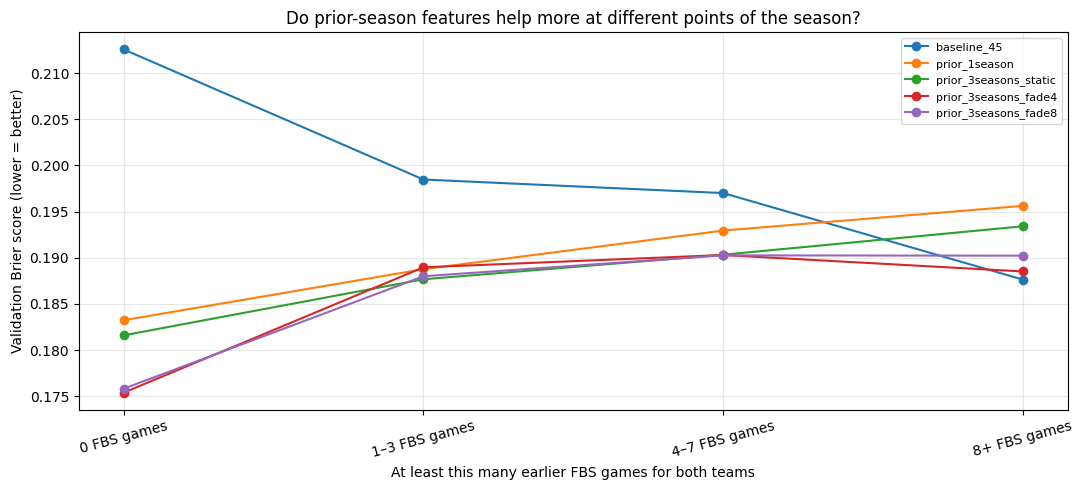

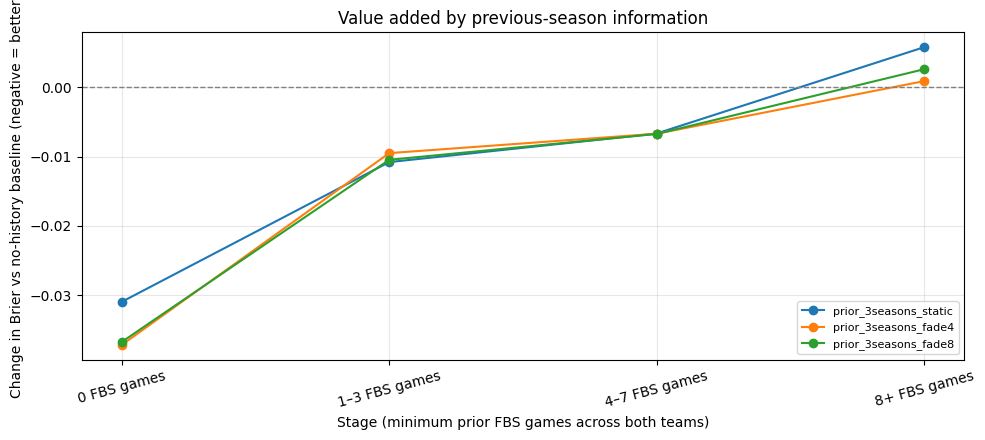

In [ ]:
stage_rows=[]
for (model,stage),grp in oof.groupby(['model','season_stage'],observed=False):
    if grp.empty: continue
    vals=metrics(grp.home_win,grp.predicted_p_home_win)
    stage_rows.append({'model':model,'season_stage':str(stage),**vals})
by_stage=pd.DataFrame(stage_rows)
assert by_stage.groupby('model').n_games.sum().eq(3646).all()
base_stages=by_stage.loc[by_stage.model.eq('baseline_45'),
                         ['season_stage','brier']].rename(columns={'brier':'baseline_brier'})
static_stages=by_stage.loc[by_stage.model.eq('prior_3seasons_static'),
                           ['season_stage','brier']].rename(columns={'brier':'static_brier'})
by_stage=by_stage.merge(base_stages,on='season_stage',validate='many_to_one').merge(
    static_stages,on='season_stage',validate='many_to_one')
by_stage['delta_vs_baseline']=by_stage.brier-by_stage.baseline_brier
by_stage['delta_vs_static']=by_stage.brier-by_stage.static_brier

print('All models: Brier by stage (same games, within each stage):')
table=by_stage.pivot(index='season_stage',columns='model',values='brier').reindex(STAGE_ORDER)
display(table.round(5))
print('Improvements against the no-history baseline (negative is better):')
display(by_stage.pivot(index='season_stage',columns='model',
                       values='delta_vs_baseline').reindex(STAGE_ORDER).round(5))
print('Validation game counts in each stage:')
display(by_stage.loc[by_stage.model.eq('baseline_45'),
                 ['season_stage','n_games']].set_index('season_stage').reindex(STAGE_ORDER))

fig,ax=plt.subplots(figsize=(11,5))
for name in FEATURE_SETS:
    s=by_stage.loc[by_stage.model.eq(name)].set_index('season_stage').reindex(STAGE_ORDER)
    ax.plot(STAGE_ORDER,s['brier'],marker='o',label=name)
ax.set(xlabel='At least this many earlier FBS games for both teams',
       ylabel='Validation Brier score (lower = better)',
       title='Do prior-season features help more at different points of the season?')
ax.grid(alpha=.3)
ax.legend(loc='best',fontsize=8)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Another view: direct gain from historical priors vs no history, by stage
fig,ax=plt.subplots(figsize=(10,4.5))
for name in ['prior_3seasons_static','prior_3seasons_fade4','prior_3seasons_fade8']:
    s=by_stage.loc[by_stage.model.eq(name)].set_index('season_stage').reindex(STAGE_ORDER)
    ax.plot(STAGE_ORDER,s['delta_vs_baseline'],marker='o',label=name)
ax.axhline(0,color='gray',linestyle='--',linewidth=1)
ax.set(xlabel='Stage (minimum prior FBS games across both teams)',
       ylabel='Change in Brier vs no-history baseline (negative = better)',
       title='Value added by previous-season information')
ax.grid(alpha=.3);ax.legend(fontsize=8)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 7. Paired game-level comparison and per-season consistency


In [ ]:
obs=oof.pivot(index=['game_id','season','home_win'],columns='model',values='predicted_p_home_win')
assert len(obs)==3646 and obs.notna().all().all()
errors=pd.DataFrame(index=obs.index)
actual=obs.index.get_level_values('home_win').to_numpy(dtype=float)
for name in FEATURE_SETS:
    errors[name]=(obs[name].to_numpy()-actual)**2

paired=[]
for name in ['baseline_45','prior_1season','prior_3seasons_fade4','prior_3seasons_fade8']:
    diff=errors[name]-errors['prior_3seasons_static']
    paired.append({'model':name,
                   'mean_squared_error_difference_vs_static':diff.mean(),
                   'games_with_smaller_squared_error_than_static':int((diff<0).sum()),
                   'games_with_larger_squared_error_than_static':int((diff>0).sum())})
print('Paired, game-by-game comparison against the static three-season history:')
display(pd.DataFrame(paired).round(6))

by_year=[]
for name in FEATURE_SETS:
    for season,grp in oof.loc[oof.model.eq(name)].groupby('season'):
        by_year.append({'model':name,'season':int(season),
                        'brier':brier_score_loss(grp.home_win,grp.predicted_p_home_win),
                        'games':len(grp)})
per_year=pd.DataFrame(by_year)
pv=per_year.pivot(index='season',columns='model',values='brier')
print('Brier difference against static 3 seasons by validation year:')
display(pv.subtract(pv['prior_3seasons_static'],axis=0).round(5))
print('Years with lower Brier than static history:')
for name in ['prior_3seasons_fade4','prior_3seasons_fade8']:
    improvement = pv[name] < pv['prior_3seasons_static']
    print(name, ':', int(improvement.sum()), 'of', len(improvement))

Paired, game-by-game comparison against the static three-season history:


,model,mean_squared_error_difference_vs_static,games_with_smaller_squared_error_than_static,games_with_larger_squared_error_than_static
0,baseline_45,0.006984,1520,2126
1,prior_1season,0.001978,1746,1900
2,prior_3seasons_fade4,-0.001704,1926,1720
3,prior_3seasons_fade8,-0.001456,1951,1695


Brier difference against static 3 seasons by validation year:


model,baseline_45,prior_1season,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static
season,,,,,
2019,0.00752,0.00343,-0.00497,-0.00326,0.0
2020,0.01106,-0.00105,0.00069,-0.00028,0.0
2021,0.00760,0.00482,-0.00202,-0.00150,0.0
2022,0.00318,0.00094,-0.00018,-0.00044,0.0
2023,0.00683,0.00085,-0.00131,-0.00144,0.0


Years with lower Brier than static history:
prior_3seasons_fade4 : 4 of 5
prior_3seasons_fade8 : 5 of 5


## 8. Save artifacts to Google Drive


In [ ]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PROCESSED.mkdir(parents=True,exist_ok=True)
outfiles={
    'enhanced_matchups': PROCESSED / 'matchup_features_history_decay.csv',
    'manifest': PROCESSED / 'history_decay_feature_manifest.json',
    'fold_scores': OUTPUT_DIR / 'history_decay_fold_scores.csv',
    'pooled_scores': OUTPUT_DIR / 'history_decay_pooled_scores.csv',
    'oof_predictions': OUTPUT_DIR / 'history_decay_oof_predictions_2019_2023.csv',
    'stage_scores': OUTPUT_DIR / 'history_decay_scores_by_stage.csv',
    'season_scores': OUTPUT_DIR / 'history_decay_scores_by_year.csv',
}
matchups.to_csv(outfiles['enhanced_matchups'],index=False)
fold_results.to_csv(outfiles['fold_scores'],index=False)
overall.to_csv(outfiles['pooled_scores'],index=False)
oof.to_csv(outfiles['oof_predictions'],index=False)
by_stage.to_csv(outfiles['stage_scores'],index=False)
per_year.to_csv(outfiles['season_scores'],index=False)
configuration={
    'purpose':'Measure when prior-season statistics matter and whether pregame fading improves performance',
    'feature_sets':FEATURE_SETS,
    'stage_variable':'minimum of home and away prior FBS-game counts',
    'stage_labels':STAGE_ORDER,
    'fade_half_lives_fbs_games':[4,8],
    'fade_equation':'2 ** (-prior_FBS_games / half_life)',
    'win_pct_neutral_anchor':0.5,
    'average_margin_neutral_anchor':0.0,
    'validation_folds':folds,
    'reserved_test_seasons':sorted(TEST_YEARS),
    'target':'home_win',
    'primary_metric':'pooled out-of-fold Brier score',
    'notebook06_reproducibility':reproducibility,
    'warning':'All historical and season-count features must be pregame. No test-season labels were evaluated.'
}
outfiles['manifest'].write_text(json.dumps(configuration,indent=2),encoding='utf-8')
print('Saved:')
for key,path in outfiles.items():print(' -',path)
print('Never scored the 2024–2025 final holdout.')

Saved:
 - /content/drive/MyDrive/CFB_Upset_Project/data/processed/matchup_features_history_decay.csv
 - /content/drive/MyDrive/CFB_Upset_Project/data/processed/history_decay_feature_manifest.json
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/history_decay_fold_scores.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/history_decay_pooled_scores.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/history_decay_oof_predictions_2019_2023.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/history_decay_scores_by_stage.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/history_decay_scores_by_year.csv
Never scored the 2024–2025 final holdout.
